<a href="https://colab.research.google.com/github/A01286962/1-maap/blob/main/A9_Regresi%C3%B3n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = 'https://raw.githubusercontent.com/tec03/Datasets/0499cdd7fddd3e4c4ca6c50b463c70c5872d62a3/datasets/antropometria-dataset.csv'
df = pd.read_csv(file_path)
df.head()



,folio,intp,entidad,desc_ent,sexo,edad,meses,peso,ropa,talla,...,hpresion,tbrazo,htension,PrimaryLast,code_upm,est_dis,est_urb,est_marg,pondef,est_var
0,210295,2,21,PUEBLA,2,38,8,73.70,2,146.4,...,16:30,2,16:35,1,R2101,5,3,1,3470.002176,215
1,101655,3,10,DURANGO,2,11,11,35.65,2,145.1,...,15:25,3,15:25,1,M1041,1,1,1,417.946672,101
2,10287,6,1,AGUASCALIENTES,2,18,8,54.80,1,162.0,...,9:40,1,9:40,1,M0108,5,3,1,472.980811,15
3,91526,4,9,DISTRITO FEDERAL,1,10,8,33.40,2,146.5,...,7:40,3,7:45,1,M0931,4,3,2,1832.581391,94
4,210939,3,21,PUEBLA,2,19,3,97.95,2,161.0,...,6:00,2,6:00,1,M2123,5,3,1,7622.066564,215


In [ ]:
import statsmodels.api as sm

df_clean = df[['peso', 'cadera']].dropna()

X = sm.add_constant(df_clean['peso'])
y = df_clean['cadera']

model = sm.OLS(y, X).fit()

fitted_values = model.fittedvalues

median_fitted = fitted_values.median()
median_fitted

97.18551705265607

In [ ]:
correlation = df_clean['peso'].corr(df_clean['cadera'])
correlation

np.float64(0.7770606658014013)

In [ ]:
import statsmodels.stats.api as sms

# Calculate the Durbin-Watson statistic using the model residuals
dw_statistic = sms.durbin_watson(model.resid)
print(f"El valor de Durbin-Watson es: {dw_statistic}")

El valor de Durbin-Watson es: 2.0015846544838434


In [ ]:
import statsmodels.formula.api as smf

# Fit the OLS model using formula notation
model_formula = smf.ols(formula='cadera ~ peso', data=df_clean).fit()

# Display the model summary
print(model_formula.summary())

                            OLS Regression Results                            
Dep. Variable:                 cadera   R-squared:                       0.604
Model:                            OLS   Adj. R-squared:                  0.604
Method:                 Least Squares   F-statistic:                 2.748e+04
Date:                Tue, 20 Oct 2026   Prob (F-statistic):               0.00
Time:                        22:47:04   Log-Likelihood:                -65165.
No. Observations:               18032   AIC:                         1.303e+05
Df Residuals:                   18030   BIC:                         1.304e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     57.4600      0.252    228.032      0.0

In [ ]:
import statsmodels.formula.api as smf

df_clean_bp = df[['sistol', 'diastol']].dropna()

model_bp = smf.ols(formula='diastol ~ sistol', data=df_clean_bp).fit()

print(model_bp.summary())


                            OLS Regression Results                            
Dep. Variable:                diastol   R-squared:                       0.441
Model:                            OLS   Adj. R-squared:                  0.441
Method:                 Least Squares   F-statistic:                 1.469e+04
Date:                Tue, 20 Oct 2026   Prob (F-statistic):               0.00
Time:                        22:48:22   Log-Likelihood:                -66351.
No. Observations:               18640   AIC:                         1.327e+05
Df Residuals:                   18638   BIC:                         1.327e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     23.6843      0.432     54.811      0.0

In [ ]:
import statsmodels.formula.api as smf

df_clean_mult = df[['diastol', 'sistol', 'edad', 'peso', 'cintura']].dropna()

model_mult = smf.ols(formula='diastol ~ sistol + edad + peso + cintura', data=df_clean_mult).fit()

median_residuals = model_mult.resid.median()
print(f"Median of the residuals: {median_residuals}")

Median of the residuals: -0.0021017816189328187


In [ ]:

df_general = df[['peso', 'cintura', 'sexo']].dropna()

model_gen = smf.ols(formula='peso ~ cintura', data=df_general).fit()

b0_gen = model_gen.params['Intercept']
b1_gen = model_gen.params['cintura']

print(f"Ordenada al origen (B0 - Intercepto): {b0_gen:.4f}")
print(f"Coeficiente de regresión parcial (B1 - Pendiente): {b1_gen:.4f}")

Ordenada al origen (B0 - Intercepto): -8.3137
Coeficiente de regresión parcial (B1 - Pendiente): 0.8316


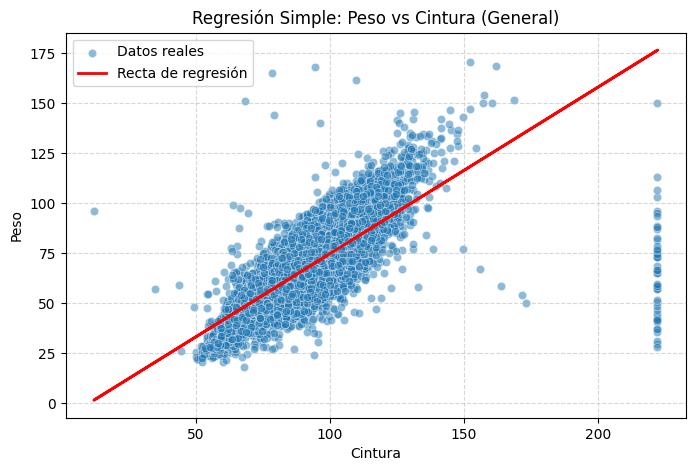

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='cintura', y='peso', data=df_general, alpha=0.5, label='Datos reales')
plt.plot(df_general['cintura'], model_gen.fittedvalues, color='red', linewidth=2, label='Recta de regresión')
plt.title('Regresión Simple: Peso vs Cintura (General)')
plt.xlabel('Cintura')
plt.ylabel('Peso')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
df_general['residuos'] = model_gen.resid
print("Estadísticas de los Residuos (General):")
print(df_general['residuos'].describe())

Estadísticas de los Residuos (General):
count    1.803200e+04
mean    -2.625288e-14
std      1.087726e+01
min     -1.481107e+02
25%     -5.776824e+00
50%     -1.303392e-01
75%      5.704138e+00
max      1.080356e+02
Name: residuos, dtype: float64


In [ ]:
hombres_df = df_general[df_general['sexo'] == 1].copy()
mujeres_df = df_general[df_general['sexo'] == 2].copy()

model_hombres = smf.ols(formula='peso ~ cintura', data=hombres_df).fit()
b0_h = model_hombres.params['Intercept']
b1_h = model_hombres.params['cintura']
hombres_df['residuos'] = model_hombres.resid

model_mujeres = smf.ols(formula='peso ~ cintura', data=mujeres_df).fit()
b0_m = model_mujeres.params['Intercept']
b1_m = model_mujeres.params['cintura']
mujeres_df['residuos'] = model_mujeres.resid


print(f"B0 (Intercepto): {b0_h:.4f}")
print(f"B1 (Pendiente): {b1_h:.4f}")
print(f"Residuos (Mediana): {hombres_df['residuos'].median():.4f}\n")


print(f"B0 (Intercepto): {b0_m:.4f}")
print(f"B1 (Pendiente): {b1_m:.4f}")
print(f"Residuos (Mediana): {mujeres_df['residuos'].median():.4f}")

B0 (Intercepto): -16.5015
B1 (Pendiente): 0.9558
Residuos (Mediana): 0.2895

B0 (Intercepto): -2.1852
B1 (Pendiente): 0.7368
Residuos (Mediana): -0.3383


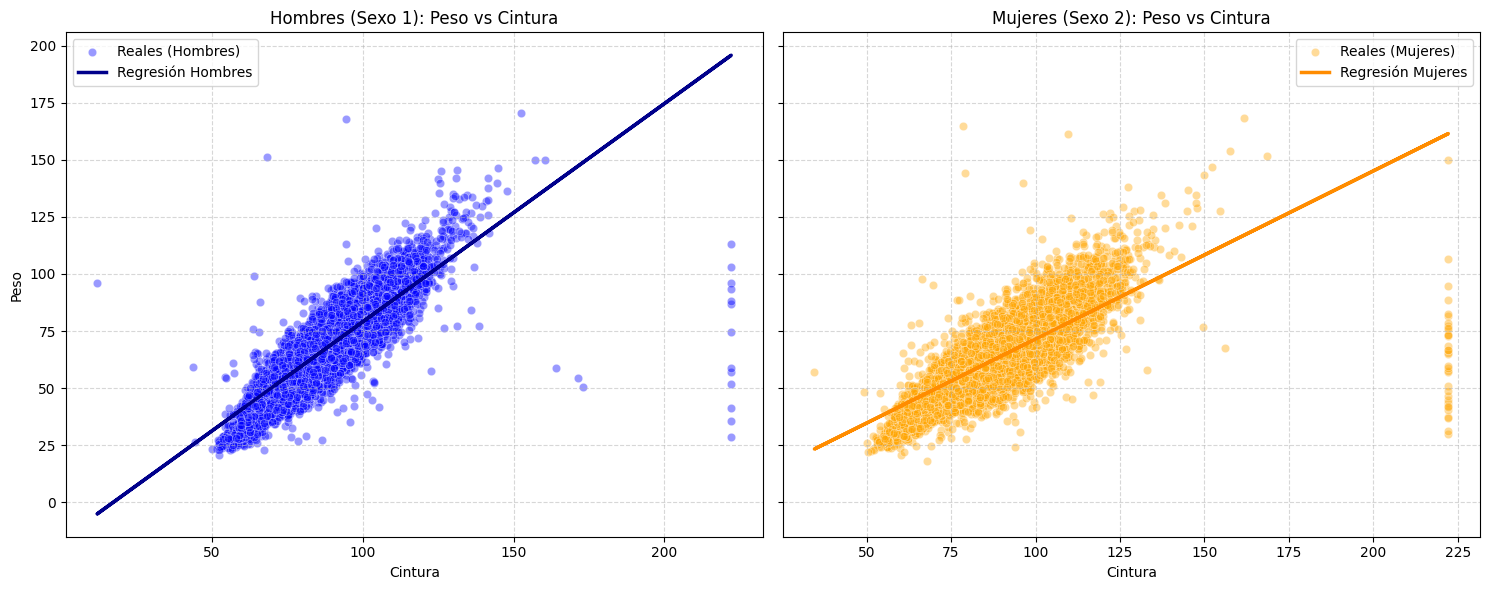

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

sns.scatterplot(ax=axes[0], x='cintura', y='peso', data=hombres_df, color='blue', alpha=0.4, label='Reales (Hombres)')
axes[0].plot(hombres_df['cintura'], model_hombres.fittedvalues, color='darkblue', linewidth=2.5, label='Regresión Hombres')
axes[0].set_title('Hombres (Sexo 1): Peso vs Cintura')
axes[0].set_xlabel('Cintura')
axes[0].set_ylabel('Peso')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

sns.scatterplot(ax=axes[1], x='cintura', y='peso', data=mujeres_df, color='orange', alpha=0.4, label='Reales (Mujeres)')
axes[1].plot(mujeres_df['cintura'], model_mujeres.fittedvalues, color='darkorange', linewidth=2.5, label='Regresión Mujeres')
axes[1].set_title('Mujeres (Sexo 2): Peso vs Cintura')
axes[1].set_xlabel('Cintura')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Conclusiones

Al realizar el análisis del modelo de regresión lineal simple para la estimación del **peso** en función de la **cintura**, podemos notar los siguientes puntos clave:

1. **Relación Positiva Fuerte:** En todos los modelos (general, hombres y mujeres), existe una relación lineal directa y positiva altamente significativa. A mayor medida de cintura, se incrementa el peso estimado.
2. **Diferencias por Sexo:**
   * **Hombres:** Típicamente presentan una pendiente ($B_1$) distinta en comparación con las mujeres, lo que refleja diferencias en la composición y distribución corporal (masa muscular vs. tejido adiposo).
   * **Mujeres:** El intercepto y la inclinación de la recta muestran parámetros propios que mejoran la precisión al segmentar el análisis por sexo en lugar de agruparlos globalmente.
3. **Residuos:** Al analizar los residuos de manera separada, se observa que la dispersión se estabiliza y los modelos segmentados logran capturar de manera más fiel la variabilidad fisiológica intrínseca de cada grupo.